# Análise Estatística de E-commerce

**Bibliotecas utilizadas:** pandas, matplotlib, seaborn e numpy.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
# 2. Ler o arquivo CSV para um DataFrame

df = pd.read_csv("ecommerce_estatistica.csv")

# Exibir as primeiras linhas
display(df.head())

# Conferir o tamanho da base
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

,Unnamed: 0,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,...,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,...,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
1,2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,...,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
2,3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...",...,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
3,4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,...,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466
4,5,Blusa + Calça Térmica Treino Futebol Criança I...,4.7,58.0,5.0,roupa zero grau,termico unissex,Sem gênero infantil,outono/inverno,"Produto ótimo , mesmo após várias lavagens não...",...,0.888889,0.006280,0.000000,0.114508,669,166,3,100.0,0.002274,0.000910


Quantidade de linhas: 295
Quantidade de colunas: 24


In [3]:
# Conferir nomes das colunas e tipos de dados
print("Colunas do DataFrame:")
print(df.columns.tolist())

print("\\nTipos de dados:")
print(df.dtypes)

print("\\nInformações gerais:")
df.info()

# Verificar valores ausentes e linhas duplicadas
print("\\nValores ausentes por coluna:")
print(df.isnull().sum())

print("\\nQuantidade de linhas duplicadas:", df.duplicated().sum())

# Estatísticas das colunas numéricas
display(df.describe())

# Criar uma cópia para preservar os dados originais
dados = df.copy()

# Converter colunas numéricas para o tipo adequado, caso necessário
colunas_numericas = ["Nota", "N_Avaliações", "Desconto", "Preço"]
for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

# Criar uma versão numérica aproximada da quantidade vendida.
mapa_vendas = {
    "+100": 100,
    "+1000": 1000,
    "+10mil": 10000,
    "+50mil": 50000,
    "+100mil": 100000,
    "+500mil": 500000,
    "+1milhão": 1000000
}

dados["Vendas_Aproximadas"] = (
    dados["Qtd_Vendidos"].astype(str).str.strip().map(mapa_vendas)
)

print("\\nPreparação concluída.")
print("Quantidade de valores não reconhecidos em Qtd_Vendidos:",
      dados["Vendas_Aproximadas"].isna().sum())

Colunas do DataFrame:
['Unnamed: 0', 'Título', 'Nota', 'N_Avaliações', 'Desconto', 'Marca', 'Material', 'Gênero', 'Temporada', 'Review1', 'Review2', 'Review3', 'Qtd_Vendidos', 'Preço', 'Nota_MinMax', 'N_Avaliações_MinMax', 'Desconto_MinMax', 'Preço_MinMax', 'Marca_Cod', 'Material_Cod', 'Temporada_Cod', 'Qtd_Vendidos_Cod', 'Marca_Freq', 'Material_Freq']
\nTipos de dados:
Unnamed: 0               int64
Título                     str
Nota                   float64
N_Avaliações           float64
Desconto               float64
Marca                      str
Material                   str
Gênero                     str
Temporada                  str
Review1                    str
Review2                    str
Review3                    str
Qtd_Vendidos               str
Preço                  float64
Nota_MinMax            float64
N_Avaliações_MinMax    float64
Desconto_MinMax        float64
Preço_MinMax           float64
Marca_Cod                int64
Material_Cod             int64
Tempora

,Unnamed: 0,Nota,N_Avaliações,Desconto,Preço,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
count,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000
mean,1003.084746,4.480678,490.511864,16.013559,130.836644,0.807659,0.053935,0.180550,0.204558,457.681356,70.047458,4.400000,2946.305085,0.012201,0.095106
std,659.415936,0.321243,1079.395818,9.928305,64.232780,0.118979,0.118929,0.162759,0.109534,240.374227,46.627681,2.590406,8068.015665,0.014018,0.074617
min,1.000000,2.300000,3.000000,5.000000,25.630000,0.000000,0.000220,0.000000,0.025153,13.000000,0.000000,0.000000,5.000000,0.000455,0.000455
25%,401.000000,4.300000,19.000000,9.000000,73.340000,0.740741,0.001983,0.065574,0.106511,263.000000,25.000000,3.000000,100.000000,0.001819,0.015462
50%,969.000000,4.500000,77.000000,11.000000,129.210000,0.814815,0.008374,0.098361,0.201784,463.000000,60.000000,3.000000,100.000000,0.007731,0.117326
75%,1581.500000,4.700000,326.000000,22.000000,179.900000,0.888889,0.035809,0.278689,0.288223,692.000000,122.000000,7.000000,1000.000000,0.010914,0.176444
max,2198.000000,5.000000,9077.000000,51.000000,326.550000,1.000000,1.000000,0.754098,0.538300,841.000000,173.000000,9.000000,50000.000000,0.042292,0.176444


\nPreparação concluída.
Quantidade de valores não reconhecidos em Qtd_Vendidos: 46


In [4]:
# 4. Análise exploratória: principais indicadores

print("RESUMO ESTATÍSTICO")
print("-" * 40)
print(f"Preço médio: R$ {dados['Preço'].mean():.2f}")
print(f"Preço mediano: R$ {dados['Preço'].median():.2f}")
print(f"Nota média: {dados['Nota'].mean():.2f}")
print(f"Desconto médio: {dados['Desconto'].mean():.2f}%")
print(f"Média de avaliações por produto: {dados['N_Avaliações'].mean():.2f}")

# Identificar produtos com maiores notas e maior número de avaliações
print("\\n5 produtos com mais avaliações:")
display(dados.nlargest(5, "N_Avaliações")[["Título", "Nota", "N_Avaliações", "Preço"]])

print("\\n10 marcas com mais produtos na base:")
display(dados["Marca"].value_counts().head(10).rename_axis("Marca").reset_index(name="Quantidade"))

RESUMO ESTATÍSTICO
----------------------------------------
Preço médio: R$ 130.84
Preço mediano: R$ 129.21
Nota média: 4.48
Desconto médio: 16.01%
Média de avaliações por produto: 490.51
\n5 produtos com mais avaliações:


,Título,Nota,N_Avaliações,Preço
30,Kit 5 Camisetas Masculinas Slim Fit Básicas A...,4.5,9077.0,239.11
266,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5691.0,199.90
149,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5688.0,199.90
205,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5688.0,199.90
1,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,199.90


\n10 marcas com mais produtos na base:


,Marca,Quantidade
0,lupo,40
1,stillger jeans,16
2,stillger,16
3,celi,15
4,menina linda,12
5,adidas,11
6,zorba,10
7,mash,9
8,própria,8
9,sawary,8


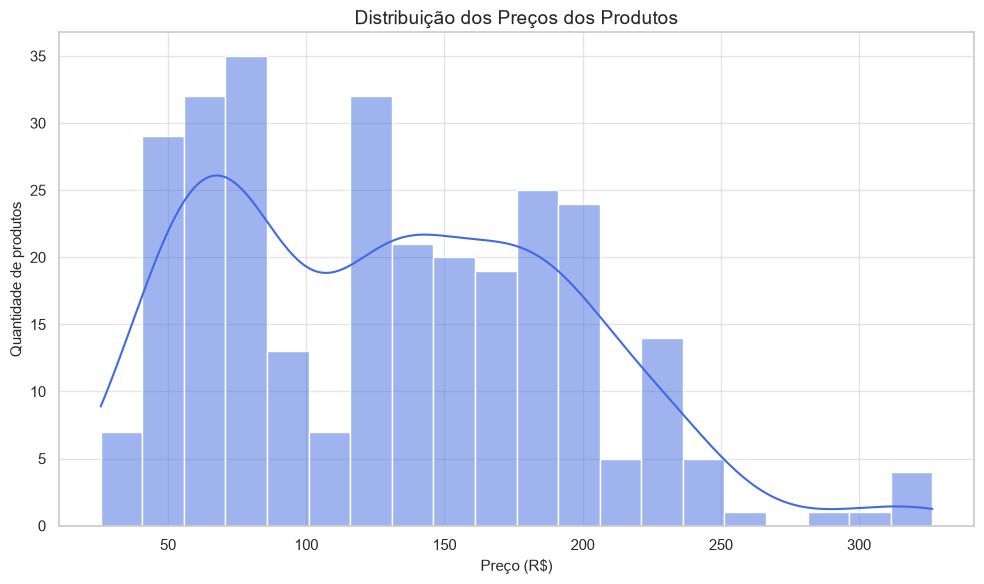

In [5]:
# GRÁFICO 1 - HISTOGRAMA
# Objetivo: observar como os preços dos produtos estão distribuídos.

plt.figure(figsize=(10, 6))
sns.histplot(data=dados, x="Preço", bins=20, kde=True, color="royalblue")
plt.title("Distribuição dos Preços dos Produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Quantidade de produtos")
plt.tight_layout()
plt.show()

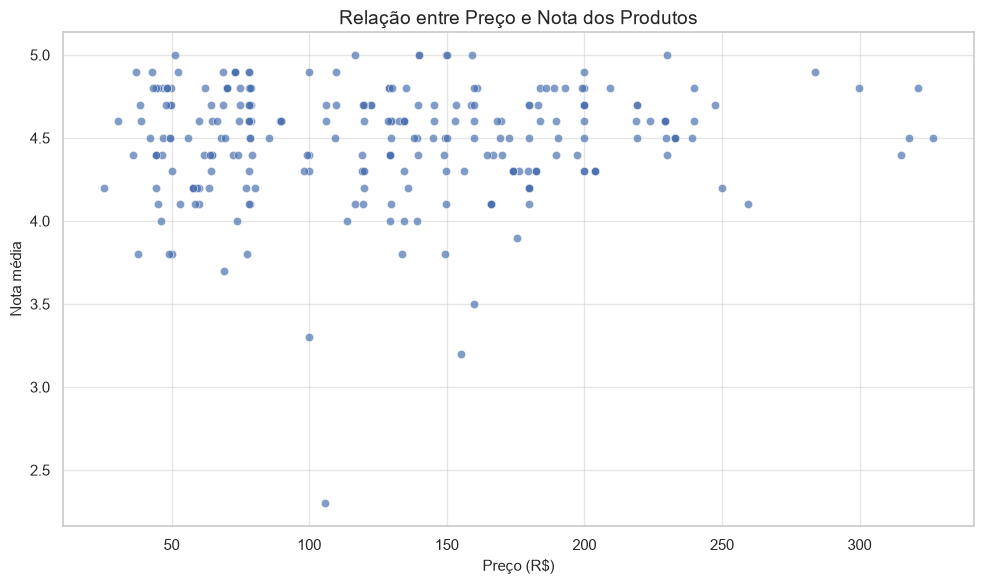

In [6]:
# GRÁFICO 2 - DISPERSÃO
# Objetivo: verificar se existe relação entre o preço e a nota dos produtos.

plt.figure(figsize=(10, 6))
sns.scatterplot(data=dados, x="Preço", y="Nota", alpha=0.7)
plt.title("Relação entre Preço e Nota dos Produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Nota média")
plt.tight_layout()
plt.show()

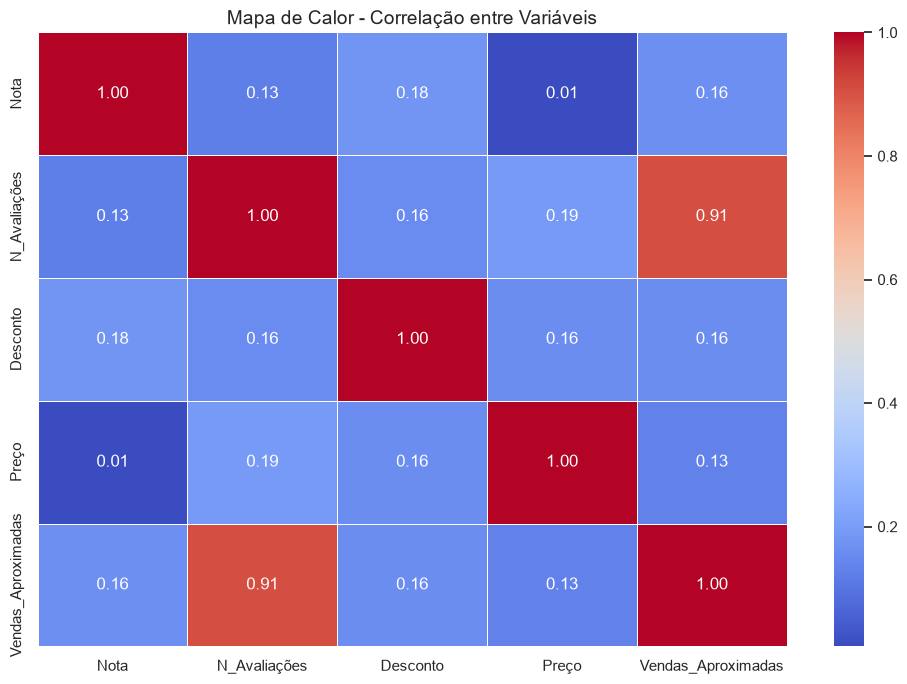

In [7]:
# GRÁFICO 3 - MAPA DE CALOR
# Objetivo: identificar correlações entre as variáveis numéricas.

colunas_correlacao = [
    "Nota", "N_Avaliações", "Desconto", "Preço", "Vendas_Aproximadas"
]

matriz_correlacao = dados[colunas_correlacao].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Mapa de Calor - Correlação entre Variáveis")
plt.tight_layout()
plt.show()

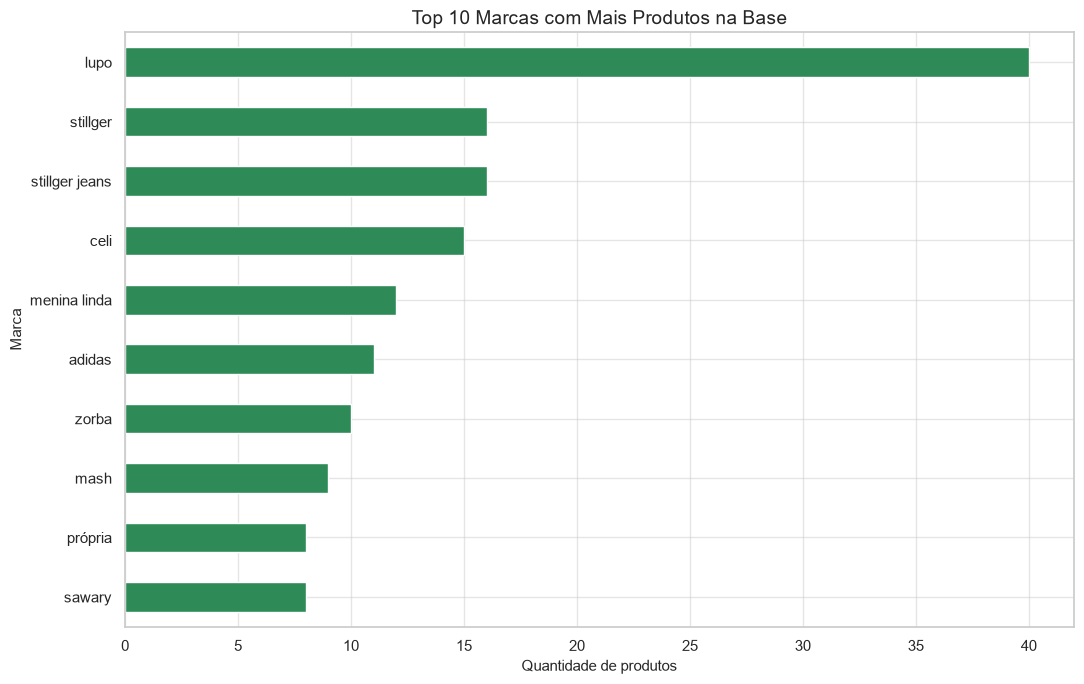

In [8]:
# GRÁFICO 4 - BARRAS
# Objetivo: destacar as 10 marcas com maior quantidade de produtos cadastrados.

top_marcas = dados["Marca"].value_counts().head(10).sort_values()

plt.figure(figsize=(11, 7))
top_marcas.plot(kind="barh", color="seagreen")
plt.title("Top 10 Marcas com Mais Produtos na Base")
plt.xlabel("Quantidade de produtos")
plt.ylabel("Marca")
plt.tight_layout()
plt.show()

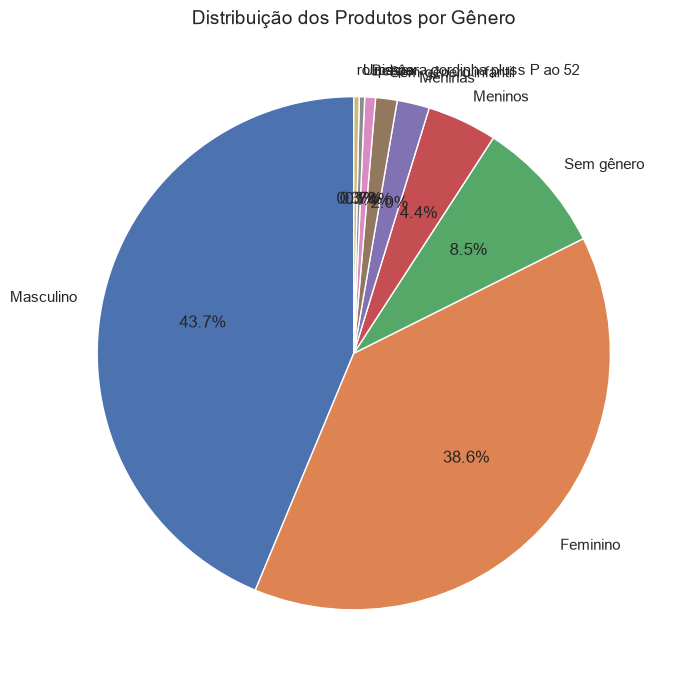

In [9]:
# GRÁFICO 5 - PIZZA
# Objetivo: visualizar a participação de cada gênero na base de produtos.

generos = dados["Gênero"].value_counts()

plt.figure(figsize=(9, 7))
plt.pie(
    generos,
    labels=generos.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribuição dos Produtos por Gênero")
plt.ylabel("")
plt.tight_layout()
plt.show()

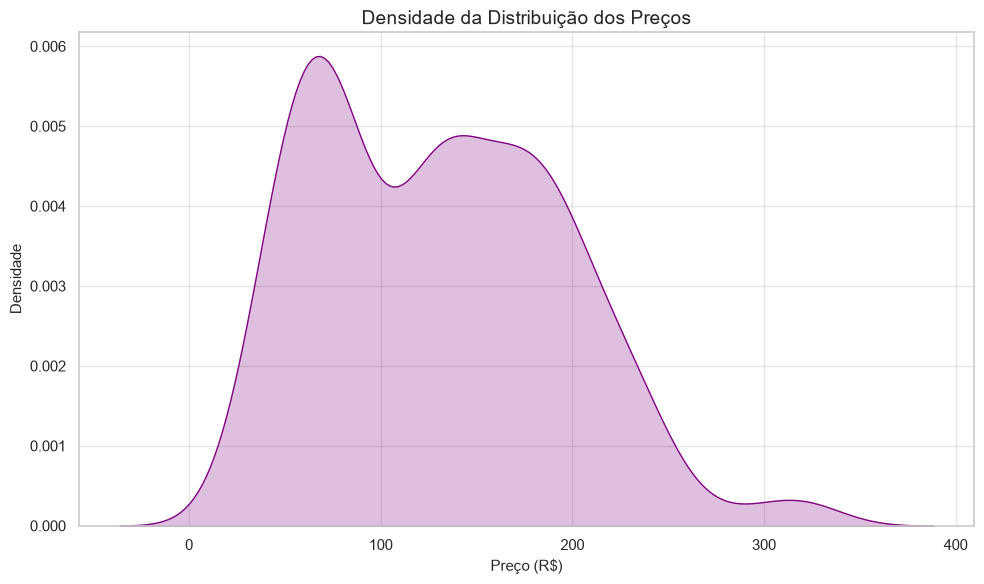

In [10]:
# GRÁFICO 6 - DENSIDADE
# Objetivo: visualizar a concentração dos preços, sem dividir os dados em intervalos.

precos_validos = dados["Preço"].dropna()

plt.figure(figsize=(10, 6))
sns.kdeplot(data=precos_validos, fill=True, color="purple")
plt.title("Densidade da Distribuição dos Preços")
plt.xlabel("Preço (R$)")
plt.ylabel("Densidade")
plt.tight_layout()
plt.show()

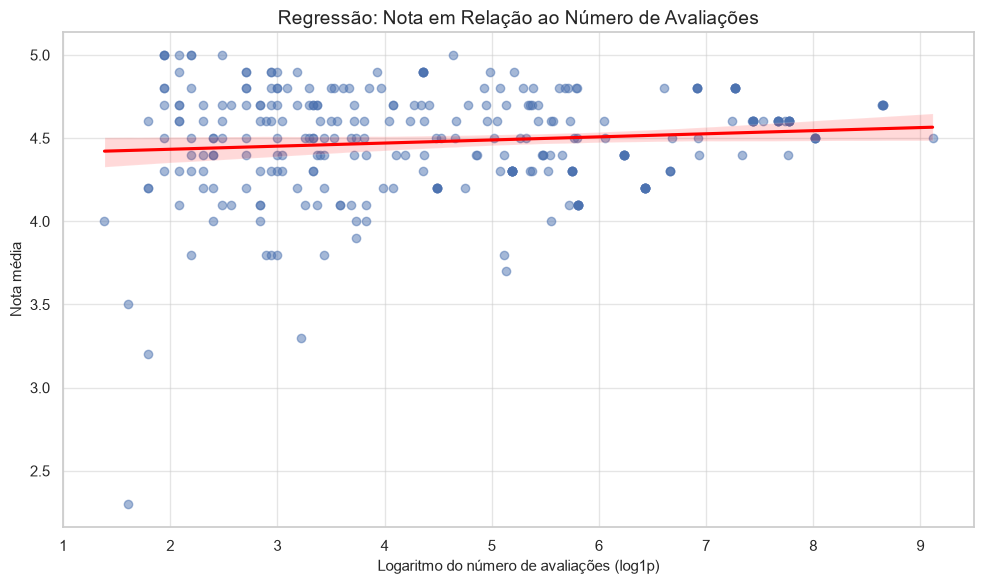

In [11]:
# GRÁFICO 7 - REGRESSÃO
# Objetivo: observar a tendência entre o número de avaliações e a nota.

dados_regressao = dados[["N_Avaliações", "Nota"]].dropna().copy()
dados_regressao["Log_Avaliações"] = np.log1p(dados_regressao["N_Avaliações"])

plt.figure(figsize=(10, 6))
sns.regplot(
    data=dados_regressao,
    x="Log_Avaliações",
    y="Nota",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)
plt.title("Regressão: Nota em Relação ao Número de Avaliações")
plt.xlabel("Logaritmo do número de avaliações (log1p)")
plt.ylabel("Nota média")
plt.tight_layout()
plt.show()

## Conclusão da análise

Com os gráficos e indicadores apresentados, é possível investigar:

- **Preços:** identificar a faixa de preço mais frequente e a concentração dos produtos.
- **Notas:** observar a avaliação geral dos produtos e sua relação com o preço.
- **Avaliações:** verificar se produtos com mais avaliações tendem a apresentar notas diferentes.
- **Correlações:** identificar relações entre preço, desconto, nota, avaliações e vendas aproximadas.
- **Marcas:** descobrir quais marcas aparecem com maior frequência na base.
- **Gêneros:** comparar a participação de cada categoria de gênero.
